## Problema - Gestión de tareas con Heap y Cola de Prioridad

## Algoritmo creativo

## Andres Matias Carballo

## Juan Felipe Herrera

## Laura Juliana Ceron 


## 1) Descripción del problema

Un centro de cómputo recibe tareas que sus servidores deben procesar, cada tarea contiene un código, nombre y prioridad(un número entero)y la tarea con la prioridad numérica mayor se procesa primero. El problema que se busca resolver es administrar las tareas de forma que siempre se pueda consultar, procesar e insertar la de mayor prioridad de manera eficiente.


## 2) Requerimientos

*Requerimientos Funcionales:* 

- *RF1:* El sistema debe pedir n tareas y registrar, para cada una, código, nombre y prioridad.

- *RF2:*
El sistema debe mostrar la lista original de prioridades en el orden ingresado.

- *RF3:*
El sistema debe construir un Max-Heap a partir de la lista original.

- *RF4:*
El sistema debe mostrar el Max-Heap como lista y como árbol sencillo en texto.

- *RF5:*
El sistema debe mostrar la tarea de mayor prioridad sin eliminarla.

- *RF6:*
El sistema debe retirar y mostrar la tarea de mayor prioridad, y reorganizar el heap.

- *RF7:*
El sistema debe permitir insertar una nueva tarea conservando la propiedad del Max-Heap.

- *RF8:*
El sistema debe ordenar las prioridades de menor a mayor con HeapSort.

- *RF9:*
El sistema debe mostrar, en HeapSort, solo la lista original, el Max-Heap y la lista ordenada.

- *RF10:*
El sistema debe poder probarse con al menos 6 tareas diferentes.


*Requerimientos Funcionales:* 

- *RFN1:*
El heap debe implementarse con un arreglo, sin nodos ni punteros.

- *RFN2:*
La inserción y HeapSort deben implementarse manualmente.

- *RFN3:*
No se permite usar heapq, sort() ni sorted().

- *-RFN4:*
El código debe estar organizado por funciones.

- *RFN5:*
Después de cada operación, el arreglo debe seguir cumpliendo la propiedad del Max-Heap(padre >= hijos).

- *RFN6:*
Las salidas deben ser claras y legibles(listas, árbol de texto y mensajes que indiquen qué operación se hizo).


## 3) Historias de usuario

**HU1.** *Como* administrador del centro de cómputo, *quiero* registrar varias tareas con su código, nombre y prioridad, *para* tener toda la carga de trabajo lista antes de procesarla.
- *Criterio de aceptación:* al ingresar las prioridades `[8, 4, 10, 3, 7]`, el programa muestra exactamente esa lista como "Lista original de prioridades".

**HU2.** *Como* administrador, *quiero* construir un Max-Heap a partir de las tareas registradas, *para* que la tarea más urgente quede siempre accesible de forma inmediata.
- *Criterio de aceptación:* a partir de `[8, 4, 10, 3, 7]`, el Max-Heap resultante es `[10, 7, 8, 3, 4]`.

**HU3.** *Como* administrador, *quiero* consultar cuál es la tarea más urgente sin quitarla de la fila, *para* decidir si el servidor puede procesarla ya.
- *Criterio de aceptación:* `MAXIMUM` muestra la tarea en la raíz sin modificar el heap.

**HU4.** *Como* administrador, *quiero* extraer y procesar la tarea más urgente, *para* que el servidor avance con su carga de trabajo.
- *Criterio de aceptación:* tras extraer la tarea de prioridad 10, el heap queda reorganizado como `[8, 7, 4, 3]`.

**HU5.** *Como* administrador, *quiero* insertar una tarea nueva en cualquier momento, *para* que el sistema la acomode automáticamente según su urgencia.
- *Criterio de aceptación:* al insertar una tarea con prioridad 12 (la más alta), esta queda ubicada en la raíz del heap.


## 4) Diagrama de flujo


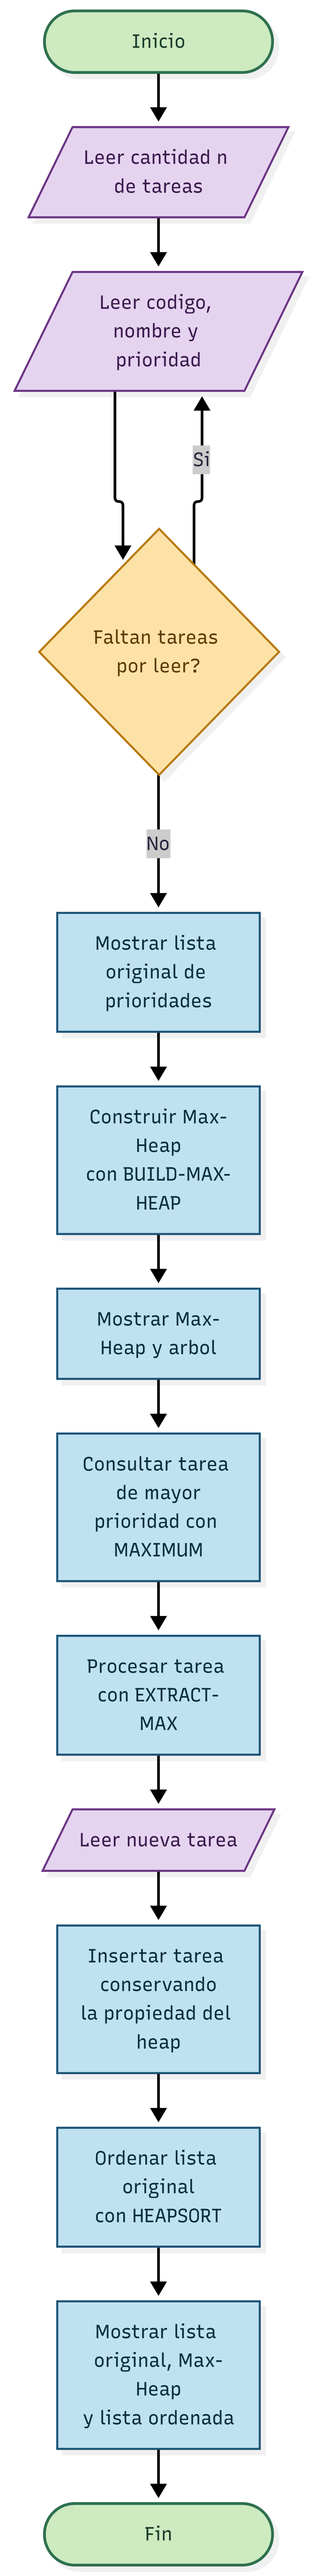

# Descripción diagrama de flujo

El programa inicia leyendo cuántas tareas se van a registrar, y entra en un bucle que pide código, nombre y prioridad de cada una hasta completar la cantidad indicada. Con la lista original ya armada, se construye el Max-Heap usando BUILD-MAX-HEAP, se muestra su representación, y se consulta la tarea de mayor prioridad sin eliminarla (MAXIMUM). Luego se procesa y extrae esa tarea con EXTRACT-MAX, se lee una tarea nueva y se inserta conservando la propiedad del heap. Finalmente, se aplica HEAPSORT sobre la lista original de prioridades y se muestran los tres resultados: la lista original, el Max-Heap construido y la lista ya ordenada.


## 5) Análisis de complejidad

### Justificación

El Max-Heap se representa con un arreglo, y por ser un árbol binario **completo** (se llena nivel por nivel), su altura siempre es `⌊log₂ n⌋`. Todas las operaciones del heap dependen de recorrer, en el peor caso, esa altura: MAX-HEAPIFY "hunde" un elemento nivel por nivel hasta una hoja, y la inserción lo "sube" nivel por nivel hasta la raíz. Por eso ambas son O(log n). BUILD-MAX-HEAP llama a MAX-HEAPIFY sobre cada nodo interno, pero la mayoría de esos nodos están cerca de las hojas, donde el trabajo real es mínimo, lo que hace que su costo total sea lineal y no logarítmico-lineal. HEAPSORT combina la construcción (lineal) con `n-1` extracciones (cada una logarítmica).

### Función T(n)

**MAX-HEAPIFY:** en el peor caso, el hijo más grande puede tener hasta `2n/3` elementos en su subárbol, por lo que:
```
T(n) = T(2n/3) + O(1)
```
Por el teorema maestro, esto da `T(n) = O(log n)`.

**BUILD-MAX-HEAP:** hay a lo sumo `⌈n/2^(h+1)⌉` nodos de altura `h`, cada uno cuesta `O(h)`:
```
T(n) = O(n · Σ h/2^h)   para h desde 0 hasta log n
```
La serie `Σ h/2^h` converge a 2 (una constante), así que `T(n) = O(n)`.

**INSERTAR:** en el peor caso recorre toda la altura del árbol subiendo nivel por nivel:
```
T(n) = O(log n)
```

**HEAPSORT:** construir el heap (`O(n)`) más `n-1` extracciones con su respectivo heapify:
```
T(n) = O(n) + Σ O(log k)   para k desde 2 hasta n
     = O(n) + O(n log n)
     = O(n log n)
```

### Mejor y peor caso

| Operación | Mejor caso Ω | Peor caso O |
| :--- | :---: | :---: |
| MAX-HEAPIFY | Ω(1) — el elemento ya cumple la propiedad de heap | O(log n) — se hunde hasta una hoja |
| BUILD-MAX-HEAP | Ω(n) | O(n) |
| MAXIMUM | Ω(1) | O(1) |
| EXTRACT-MAX | Ω(1) — el elemento que sube ya es válido | O(log n) — se hunde hasta una hoja |
| INSERTAR | Ω(1) — la nueva prioridad es menor que su padre | O(log n) — sube hasta la raíz |
| **HEAPSORT (total)** | **Ω(n log n)** | **O(n log n)** |


### Gráfica

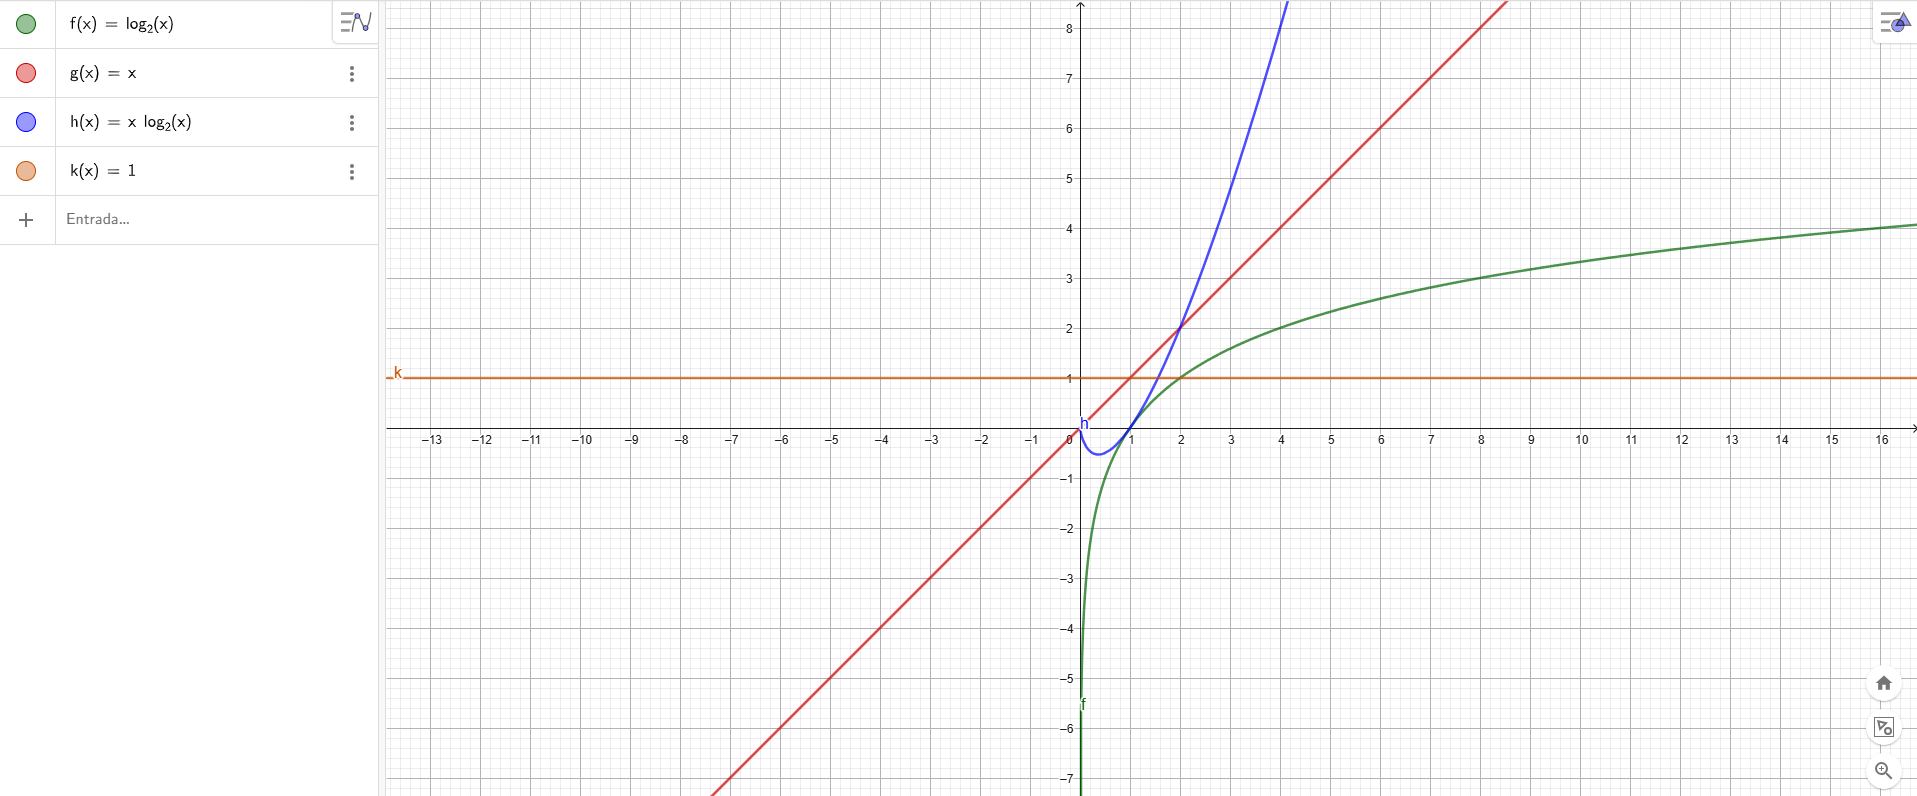

## 6) Código funcional


In [1]:
def pedir_entero(mensaje, minimo=None, maximo=None):
    while True:
        try:
            texto = input(mensaje).strip()
            if texto == "":
                print("El campo no puede estar vacío.")
                continue
            valor = int(texto)
            if minimo is not None and valor < minimo:
                print(f"El valor debe ser mayor o igual a {minimo}.")
                continue
            if maximo is not None and valor > maximo:
                print(f"El valor debe ser menor o igual a {maximo}.")
                continue
            return valor
        except ValueError:
            print("Entrada inválida. Digite un número entero.")
        except (EOFError, KeyboardInterrupt):
            print("Entrada no disponible.")
            return None


def pedir_texto(mensaje):
    while True:
        try:
            texto = input(mensaje).strip()
            if texto != "":
                return texto
            print("El campo no puede estar vacío.")
        except (EOFError, KeyboardInterrupt):
            print("Entrada no disponible.")
            return None


def max_heapify(heap, i, tam=None):
    if tam is None:
        tam = len(heap)
    mayor = i
    izq = 2 * i + 1
    der = 2 * i + 2

    if izq < tam and heap[izq]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = izq
    if der < tam and heap[der]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = der

    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor, tam)


def build_max_heap(heap):
    n = len(heap)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(heap, i, n)


def maximum(heap):
    return heap[0]


def extract_max(heap):
    extraido = heap[0]
    ultimo = heap.pop()
    if heap:
        heap[0] = ultimo
        max_heapify(heap, 0)
    return extraido


def insertar_tarea(heap, tarea):
    heap.append(tarea)
    i = len(heap) - 1
    padre = (i - 1) // 2
    while i > 0 and heap[padre]["prioridad"] < heap[i]["prioridad"]:
        heap[i], heap[padre] = heap[padre], heap[i]
        i = padre
        padre = (i - 1) // 2


def heapsort(lista_tareas):
    heap = list(lista_tareas)
    build_max_heap(heap)
    heap_construido = list(heap)
    n = len(heap)
    for fin in range(n - 1, 0, -1):
        heap[0], heap[fin] = heap[fin], heap[0]
        max_heapify(heap, 0, fin)
    return heap_construido, heap


def mostrar_prioridades(heap):
    return [t["prioridad"] for t in heap]


def mostrar_arbol(heap):
    n = len(heap)
    nivel = 0
    i = 0
    while i < n:
        fin_nivel = min(i + 2 ** nivel, n)
        valores = [str(heap[j]["prioridad"]) for j in range(i, fin_nivel)]
        print("  " * (4 - nivel) + "  ".join(valores))
        i = fin_nivel
        nivel += 1


def leer_tareas():
    cantidad = pedir_entero("Ingrese la cantidad de tareas: ", minimo=1, maximo=100)
    if cantidad is None:
        return None
    tareas = []
    for i in range(1, cantidad + 1):
        codigo = pedir_texto(f"Código de la tarea {i}: ")
        if codigo is None:
            return None
        nombre = pedir_texto(f"Nombre de la tarea {i}: ")
        if nombre is None:
            return None
        prioridad = pedir_entero(f"Prioridad de la tarea {i}: ", minimo=0, maximo=1000)
        if prioridad is None:
            return None
        tareas.append({"codigo": codigo, "nombre": nombre, "prioridad": prioridad})
    return tareas


def ejecutar_demo(tareas):
    print("\nLista original de prioridades:", mostrar_prioridades(tareas))

    heap = list(tareas)
    build_max_heap(heap)
    print("\nMax-Heap:", mostrar_prioridades(heap))
    mostrar_arbol(heap)

    m = maximum(heap)
    print(f"\nTarea de mayor prioridad: {m['codigo']} - {m['nombre']} Prioridad: {m['prioridad']}")

    procesada = extract_max(heap)
    print(f"\nTarea procesada: {procesada['codigo']} - {procesada['nombre']}")
    print("Nuevo Heap:", mostrar_prioridades(heap))

    print("\n--- Insertar nueva tarea ---")
    codigo = pedir_texto("Código de la nueva tarea: ")
    if codigo is None:
        return
    nombre = pedir_texto("Nombre de la nueva tarea: ")
    if nombre is None:
        return
    prioridad = pedir_entero("Prioridad de la nueva tarea: ", minimo=0, maximo=1000)
    if prioridad is None:
        return

    nueva = {"codigo": codigo, "nombre": nombre, "prioridad": prioridad}
    insertar_tarea(heap, nueva)
    print("Heap tras la inserción:", mostrar_prioridades(heap))
    print(f"La prioridad {prioridad} quedó en la posición {heap.index(nueva)}.")

    heap_construido, ordenado = heapsort(tareas)
    print("\n--- HeapSort sobre la lista original ---")
    print("Lista original:", mostrar_prioridades(tareas))
    print("Max-Heap:", mostrar_prioridades(heap_construido))
    print("Lista ordenada:", mostrar_prioridades(ordenado))


if __name__ == "__main__":
    try:
        tareas = leer_tareas()
        if tareas is not None:
            ejecutar_demo(tareas)
    except Exception as error:
        print(f"Ocurrió un error inesperado ({error}). El programa finaliza de forma segura.")


Lista original de prioridades: [8, 4, 10, 3, 7]

Max-Heap: [10, 7, 8, 3, 4]
        10
      7  8
    3  4

Tarea de mayor prioridad: T03 - Renderizar video Prioridad: 10

Tarea procesada: T03 - Renderizar video
Nuevo Heap: [8, 7, 4, 3]

--- Insertar nueva tarea ---
Heap tras la inserción: [12, 8, 4, 3, 7]
La prioridad 12 quedó en la posición 0.

--- HeapSort sobre la lista original ---
Lista original: [8, 4, 10, 3, 7]
Max-Heap: [10, 7, 8, 3, 4]
Lista ordenada: [3, 4, 7, 8, 10]


## 7) Tests aplicados


In [2]:
def test(caso, got_output, expected_output):
    assert got_output == expected_output, f"Fallo en '{caso}': se obtuvo {got_output}, pero se esperaba {expected_output}"
    print(f"Paso caso de prueba: {caso} | Salida: {got_output}")


tarea = lambda c, n, p: {"codigo": c, "nombre": n, "prioridad": p}

tareas_enunciado = [
    tarea("T01", "Compilar proyecto", 8),
    tarea("T02", "Generar backup", 4),
    tarea("T03", "Renderizar video", 10),
    tarea("T04", "Procesar correos", 3),
    tarea("T05", "Ejecutar pruebas", 7),
]

test("Lista original de prioridades", mostrar_prioridades(tareas_enunciado), [8, 4, 10, 3, 7])

heap = list(tareas_enunciado)
build_max_heap(heap)
test("BUILD-MAX-HEAP sobre el ejemplo del enunciado", mostrar_prioridades(heap), [10, 7, 8, 3, 4])

test("MAXIMUM no elimina la raíz", maximum(heap)["prioridad"], 10)
test("MAXIMUM no modifica el heap", mostrar_prioridades(heap), [10, 7, 8, 3, 4])

procesada = extract_max(heap)
test("EXTRACT-MAX retorna la tarea correcta", procesada["codigo"], "T03")
test("EXTRACT-MAX reorganiza el heap", mostrar_prioridades(heap), [8, 7, 4, 3])

insertar_tarea(heap, tarea("T06", "Actualizar servidor", 12))
test("Insertar la prioridad más alta la deja en la raíz", heap[0]["prioridad"], 12)

heap_construido, ordenado = heapsort(tareas_enunciado)
test("HEAPSORT - Max-Heap intermedio", mostrar_prioridades(heap_construido), [10, 7, 8, 3, 4])
test("HEAPSORT - lista ordenada ascendente", mostrar_prioridades(ordenado), [3, 4, 7, 8, 10])

heap_un_nodo = [tarea("TX", "Única tarea", 5)]
test("Heap de un solo elemento es su propio máximo", maximum(heap_un_nodo)["prioridad"], 5)
extraida_unica = extract_max(heap_un_nodo)
test("Extraer el único elemento deja el heap vacío", heap_un_nodo, [])

print("\nTodos los casos de prueba pasaron correctamente.")

Paso caso de prueba: Lista original de prioridades | Salida: [8, 4, 10, 3, 7]
Paso caso de prueba: BUILD-MAX-HEAP sobre el ejemplo del enunciado | Salida: [10, 7, 8, 3, 4]
Paso caso de prueba: MAXIMUM no elimina la raíz | Salida: 10
Paso caso de prueba: MAXIMUM no modifica el heap | Salida: [10, 7, 8, 3, 4]
Paso caso de prueba: EXTRACT-MAX retorna la tarea correcta | Salida: T03
Paso caso de prueba: EXTRACT-MAX reorganiza el heap | Salida: [8, 7, 4, 3]
Paso caso de prueba: Insertar la prioridad más alta la deja en la raíz | Salida: 12
Paso caso de prueba: HEAPSORT - Max-Heap intermedio | Salida: [10, 7, 8, 3, 4]
Paso caso de prueba: HEAPSORT - lista ordenada ascendente | Salida: [3, 4, 7, 8, 10]
Paso caso de prueba: Heap de un solo elemento es su propio máximo | Salida: 5
Paso caso de prueba: Extraer el único elemento deja el heap vacío | Salida: []

Todos los casos de prueba pasaron correctamente.
